# Calibrazione microfono Behringer ECM8000

Notebook complementare al workflow di misura (`Progetto/metodo/00_workflow_misure.md` § 3).

**Principio:** la differenza in dB fra la risposta misurata di un riferimento (sorgente nota) e la sua curva di datasheet è — a meno della catena audio già compensata via loopback — la non-linearità del microfono.

**Input:**
- `data/reference/YamahaHS5_datasheet.csv` — curva di riferimento digitalizzata da WebPlotDigitizer. Il file contiene due dataset affiancati (`DIGIT#1` colonne 1-2, `DIGIT#2` colonne 3-4): usiamo solo **DIGIT#2** (colonne 3 e 4).
- `data/calibration/txt/Cal_ESS_02_ECM8000.txt` — export REW della misura del riferimento con ECM8000 (3 colonne `freq | dB | phase`, prime ~14 righe di header).

**Output:** `data/calibration/ecm8000_mic.cal` da caricare in REW come *Mic cal file*.

## 1. Caricamento e pulizia del riferimento (HS5 datasheet)

Il CSV di WebPlotDigitizer (con due dataset affiancati) ha questa struttura:
```
DIGIT#1,,DIGIT#2,
X,Y,X,Y
<f>,<dB>,<f>,<dB>
...
```
I dataset hanno lunghezze diverse, quindi alcune righe avranno campi vuoti nelle colonne 3-4. `np.genfromtxt` con `filling_values=np.nan` gestisce i mancanti che poi vengono filtrati.

I dati possono non essere ordinati per frequenza (dipende dall'ordine in cui si è cliccato sul grafico) e possono contenere punti spuri se la calibrazione degli assi è stata sbagliata in fase di digitalizzazione. Qui ordino e filtro alla banda audio.

Punti caricati da DIGIT#2: 148
Range X grezzo: 3.119 ... 19521.893
Scartati 52 punti fuori dalla banda audio [20.0, 22000.0] Hz — probabile errore di calibrazione assi in WebPlotDigitizer.
Punti finali: 96, range 20.8–19521.9 Hz, -3.7–4.2 dB


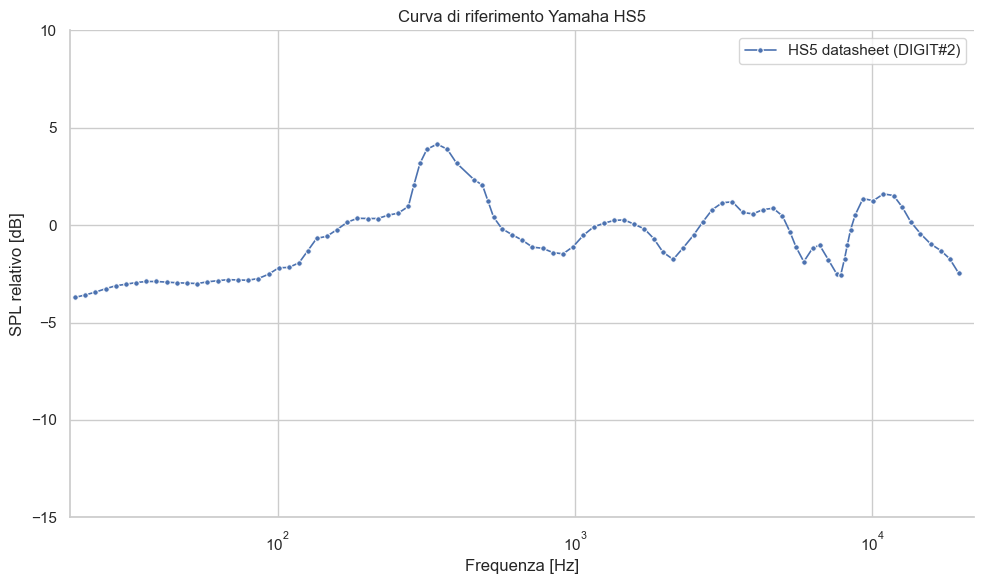

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / 'src'))
from rew_io import CAL_DIR, CAL_TXT_DIR, REF_DIR, FIG_DIR, load_rew_export, write_cal_file

sns.set_theme(style='whitegrid', context='notebook',
              rc={'axes.spines.top': False, 'axes.spines.right': False})
PALETTE = sns.color_palette('deep')


REF_FILE = REF_DIR / 'YamahaHS5_datasheet.csv'

# --- Caricamento WebPlotDigitizer CSV: solo DIGIT#2 (colonne 3 e 4) --------
ref_raw = np.genfromtxt(REF_FILE, delimiter=',', skip_header=2,
                        usecols=(2, 3), filling_values=np.nan)
mask_notnan = ~np.isnan(ref_raw).any(axis=1)
ref_raw = ref_raw[mask_notnan]
f_ref_raw, dB_ref_raw = ref_raw[:, 0], ref_raw[:, 1]
print(f'Punti caricati da DIGIT#2: {len(f_ref_raw)}')
print(f'Range X grezzo: {f_ref_raw.min():.3f} ... {f_ref_raw.max():.3f}')

# --- Filtro banda audio + ordinamento --------------------------------------
F_MIN_AUDIO, F_MAX_AUDIO = 20.0, 22000.0
mask_valid = (f_ref_raw >= F_MIN_AUDIO) & (f_ref_raw <= F_MAX_AUDIO)
n_dropped = (~mask_valid).sum()
if n_dropped:
    print(f'Scartati {n_dropped} punti fuori dalla banda audio '
          f'[{F_MIN_AUDIO}, {F_MAX_AUDIO}] Hz — '
          'probabile errore di calibrazione assi in WebPlotDigitizer.')

f_ref = f_ref_raw[mask_valid]
dB_ref = dB_ref_raw[mask_valid]

order = np.argsort(f_ref)
f_ref, dB_ref = f_ref[order], dB_ref[order]
print(f'Punti finali: {len(f_ref)}, '
      f'range {f_ref.min():.1f}–{f_ref.max():.1f} Hz, '
      f'{dB_ref.min():.1f}–{dB_ref.max():.1f} dB')

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(x=f_ref, y=dB_ref, marker='o', markersize=4, linewidth=1.2,
             color=PALETTE[0], ax=ax, label='HS5 datasheet (DIGIT#2)')
ax.set_xscale('log')
ax.set_xlabel('Frequenza [Hz]')
ax.set_ylabel('SPL relativo [dB]')
ax.set_title('Curva di riferimento Yamaha HS5')
ax.set_xlim(20, 22000)
ax.set_ylim(-15, 10)
plt.tight_layout()
plt.show()

## 2. Verifica della calibrazione loopback della scheda audio

Confronto delle due misure di sweep loopback: una con `.cal` della scheda **non** caricato (mostra la risposta nativa $H_\text{sc}(f)$ della catena DAC→ADC), l'altra con `.cal` caricato (deve risultare piatta entro ±0.2 dB se la calibrazione è corretta).

**Input attesi (esportati da REW: `File → Export → Export measurement as text`):**
- `data/calibration/txt/ESS_NoCalibration.txt` — sweep loopback senza `.cal` scheda;
- `data/calibration/txt/ESS_Calibrated.txt` — sweep loopback con `.cal` scheda caricato.

I file `.mdat` di REW sono Java serialized objects e non sono leggibili direttamente da Python — apri ciascuno in REW ed esegui l'export come testo prima di eseguire la cella sotto.

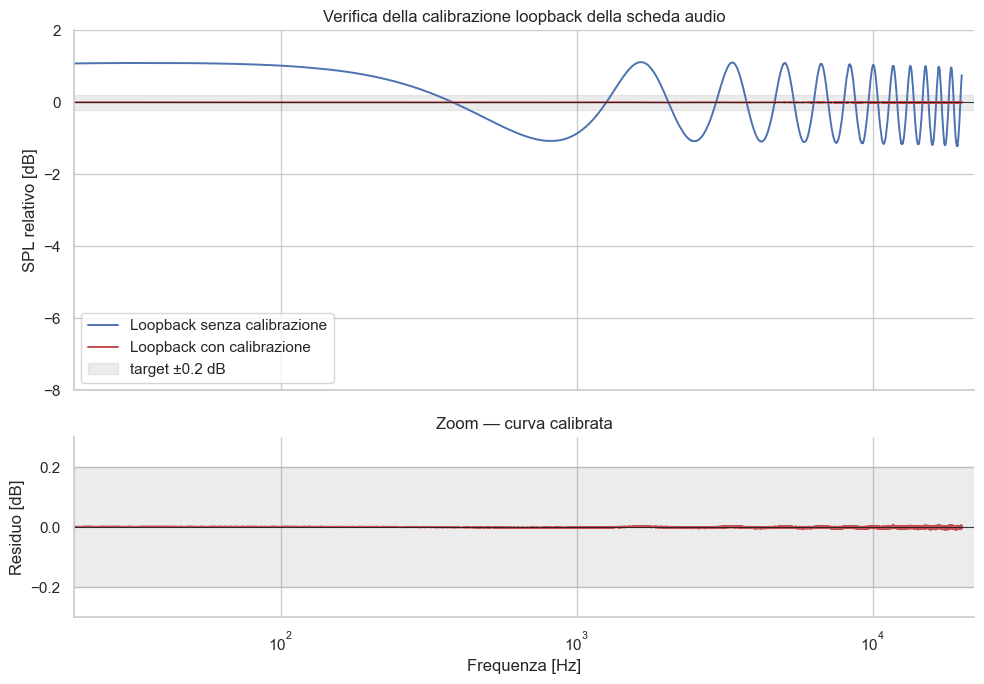

Calibrated trace: ripple picco-picco = 0.02 dB, RMS = 0.00 dB nella banda 20 Hz - 20 kHz.
OK — calibrazione entro target (±0.2 dB).


In [6]:
ESS_NOCAL = CAL_TXT_DIR / 'ESS_NoCalibration.txt'
ESS_CAL   = CAL_TXT_DIR / 'ESS_Calibrated.txt'

for p in (ESS_NOCAL, ESS_CAL):
    if not p.exists():
        raise FileNotFoundError(
            f'{p} non trovato. Apri il rispettivo .mdat in REW e fai '
            'File → Export → Export measurement as text.'
        )

f_nocal, dB_nocal = load_rew_export(ESS_NOCAL)
f_cal,   dB_cal   = load_rew_export(ESS_CAL)

# Normalizzo a 0 dB nella banda piatta 200 Hz – 2 kHz, per leggere lo scarto
# come deviazione dalla risposta media e non come livello assoluto.
def normalize(f, dB, f1=200.0, f2=2000.0):
    mask = (f >= f1) & (f <= f2)
    return dB - np.mean(dB[mask])

dB_nocal_n = normalize(f_nocal, dB_nocal)
dB_cal_n   = normalize(f_cal,   dB_cal)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                                gridspec_kw={'height_ratios': [2, 1]})

sns.lineplot(x=f_nocal, y=dB_nocal_n, ax=ax1, linewidth=1.4,
             color=PALETTE[0], label='Loopback senza calibrazione')
sns.lineplot(x=f_cal,   y=dB_cal_n,   ax=ax1, linewidth=1.4,
             color=PALETTE[3], label='Loopback con calibrazione')
ax1.set_xscale('log')
ax1.axhline(0, color='k', lw=0.6)
ax1.axhspan(-0.2, 0.2, color='gray', alpha=0.15, label='target ±0.2 dB')
ax1.set_ylabel('SPL relativo [dB]')
ax1.set_title('Verifica della calibrazione loopback della scheda audio')
ax1.set_ylim(-8, 2)
ax1.legend(loc='best')

sns.lineplot(x=f_cal, y=dB_cal_n, ax=ax2, linewidth=1.4, color=PALETTE[3])
ax2.set_xscale('log')
ax2.axhline(0, color='k', lw=0.6)
ax2.axhspan(-0.2, 0.2, color='gray', alpha=0.15)
ax2.set_xlabel('Frequenza [Hz]')
ax2.set_ylabel('Residuo [dB]')
ax2.set_title('Zoom — curva calibrata')
ax2.set_xlim(20, 22000)
ax2.set_ylim(-0.3, 0.3)

plt.tight_layout()
plt.show()

# Metrica quantitativa
mask_audio = (f_cal >= 20) & (f_cal <= 20000)
ripple = dB_cal_n[mask_audio].max() - dB_cal_n[mask_audio].min()
rms    = np.sqrt(np.mean(dB_cal_n[mask_audio]**2))
print(f'Calibrated trace: ripple picco-picco = {ripple:.2f} dB, '
      f'RMS = {rms:.2f} dB nella banda 20 Hz - 20 kHz.')
if ripple < 0.4:
    print('OK — calibrazione entro target (±0.2 dB).')
else:
    print('Ripple sopra il target: verifica setup (livelli, sample rate, cavo).')

## 3. Calcolo del file di calibrazione microfono

Da eseguire dopo aver misurato la HS5 con l'ECM8000 in REW ed esportato la misura come `data/calibration/txt/Cal_ESS_02_ECM8000.txt`.

Offset verticale rimosso: +89.36 dB
Salvato: /Users/matteob/Library/CloudStorage/GoogleDrive-matteobernardi001@gmail.com/Il mio Drive/Files/Università/Master/Illuminotecnica:Acustica/Progetto/misc/ecm8000_mic.cal


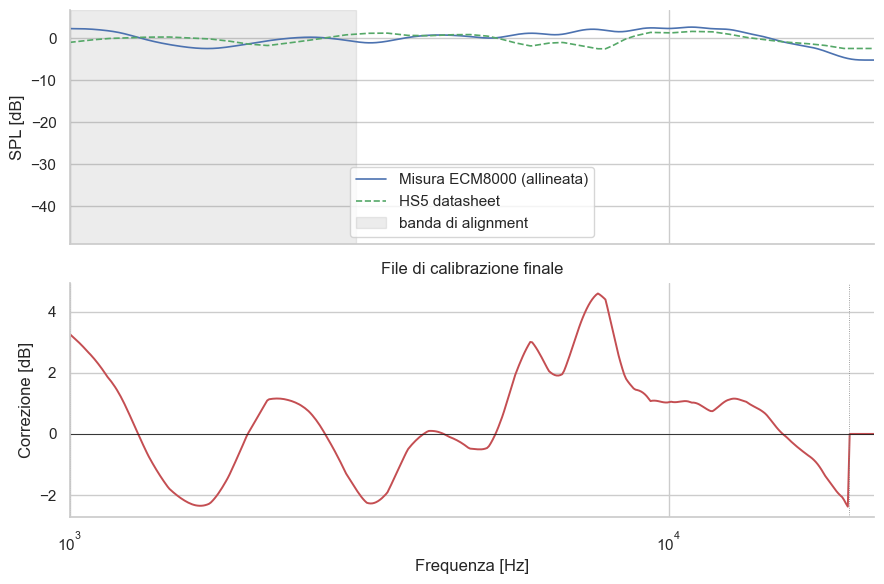

In [7]:
MEAS_FILE = CAL_TXT_DIR / 'Cal_ESS_02_ECM8000.txt'
OUT_FILE  = CAL_DIR / 'ecm8000_mic.cal'

F_LOW   = 1000.0          # sotto: capsula intrinsecamente piatta -> cal=0
F_HIGH  = 20000.0         # sopra: ECM8000 non affidabile -> cal=0
F_ALIGN = (1000.0, 3000.0)  # banda per allineamento verticale

if not MEAS_FILE.exists():
    raise FileNotFoundError(
        f'{MEAS_FILE} non esiste — esegui prima la misura in REW '
        'ed esporta con File → Export → Export measurement as text.'
    )

f_meas, dB_meas = load_rew_export(MEAS_FILE)

dB_ref_on_meas = np.interp(f_meas, f_ref, dB_ref)

mask_align = (f_meas >= F_ALIGN[0]) & (f_meas <= F_ALIGN[1])
offset = np.mean(dB_meas[mask_align]) - np.mean(dB_ref_on_meas[mask_align])
dB_meas_aligned = dB_meas - offset
print(f'Offset verticale rimosso: {offset:+.2f} dB')

cal_db = dB_meas_aligned - dB_ref_on_meas
cal_db = np.where((f_meas >= F_LOW) & (f_meas <= F_HIGH), cal_db, 0.0)
phase  = np.zeros_like(f_meas)

header = ('ECM8000 microphone calibration\n'
          f'Generated from {MEAS_FILE.name} vs {REF_FILE.name}\n'
          'Format: freq[Hz]  dB  phase[deg]')
write_cal_file(OUT_FILE, f_meas, cal_db, phase, note=header)
print(f'Salvato: {OUT_FILE}')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

sns.lineplot(x=f_meas, y=dB_meas_aligned, ax=ax1, linewidth=1.2,
             color=PALETTE[0], label='Misura ECM8000 (allineata)')
sns.lineplot(x=f_meas, y=dB_ref_on_meas, ax=ax1, linewidth=1.2,
             color=PALETTE[2], linestyle='--', label='HS5 datasheet')
ax1.set_xscale('log')
ax1.axvspan(*F_ALIGN, alpha=0.15, color='gray', label='banda di alignment')
ax1.set_ylabel('SPL [dB]')
ax1.legend(loc='lower center')

sns.lineplot(x=f_meas, y=cal_db, ax=ax2, linewidth=1.4, color=PALETTE[3])
ax2.set_xscale('log')
ax2.axhline(0, color='k', lw=0.6)
ax2.axvline(F_LOW,  color='gray', lw=0.6, ls=':')
ax2.axvline(F_HIGH, color='gray', lw=0.6, ls=':')
ax2.set_xlabel('Frequenza [Hz]')
ax2.set_ylabel('Correzione [dB]')
ax2.set_title('File di calibrazione finale')
ax2.set_xlim(1000, 22000)

plt.tight_layout()
plt.show()

## Note

- `skiprows=14` per `measure.txt` corrisponde al formato standard di export REW. Verificare nel file salvato e correggere se necessario.
- Il `.cal` risultante ha 3 colonne separate da spazi: `freq dB phase`. Caricabile in REW da `Preferences → Cal files → Mic cal file → Browse`.
- Dopo aver caricato il `.cal`, rimisurare il riferimento senza toccare il setup: la nuova curva deve aderire al datasheet entro ~1–2 dB nella banda di calibrazione.